In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Go to the project root, wherever the notebook is
project = r"C:\Users\hp\OneDrive\Desktop\citibike-operations-dashboard"
os.chdir(project)
print("Working folder:", os.getcwd())
print("Data files:", os.listdir("data"))

daily = pd.read_csv('data/daily_summary.csv', parse_dates=['trip_date'])
stations = pd.read_csv('data/station_imbalance.csv')
print(daily.shape, stations.shape)
print(daily.dtypes)

Working folder: C:\Users\hp\OneDrive\Desktop\citibike-operations-dashboard
Data files: ['daily_summary.csv', 'hourly_patterns.csv', 'station_imbalance.csv']
(730, 13) (488, 11)
trip_date           datetime64[ns]
year                         int64
month                        int64
day_name                    object
is_weekend                    bool
trips                        int64
subscriber_trips             int64
customer_trips               int64
median_trip_min            float64
avg_temp_f                 float64
precip_in                  float64
rain_day                      bool
snow_day                      bool
dtype: object


In [5]:
temporary = stations['station_name'].str.contains('Valet|Mobile|Depot', case=False)

stations['station_type'] = np.select(
    [temporary, stations['active_days'] >= 365],
    ['Temporary', 'Established'],
    default='Newer (<365 days)'
)

stations['status'] = pd.cut(
    stations['avg_daily_net_flow'],
    bins=[-np.inf, -5, 5, np.inf],
    labels=['Runs out of bikes', 'Balanced', 'Fills up']
)

print(stations['station_type'].value_counts())
print(stations[stations['station_type'] == 'Established']['status'].value_counts())

stations.to_csv('data/station_imbalance_clean.csv', index=False)

station_type
Established          331
Newer (<365 days)    152
Temporary              5
Name: count, dtype: int64
status
Balanced             282
Fills up              26
Runs out of bikes     23
Name: count, dtype: int64


In [6]:
yearly = daily.groupby('year')['trips'].sum()
print(yearly)
print(f"YoY growth 2015 vs 2014: {(yearly[2015] / yearly[2014] - 1) * 100:.1f}%")

year
2014    8069008
2015    9908092
Name: trips, dtype: int64
YoY growth 2015 vs 2014: 22.8%


            count     mean
temp_band                 
Below 40°F    176  10078.0
40-60°F       220  22773.0
60-75°F       218  32585.0
75°F+         116  35257.0

Correlation (temperature vs trips): 0.80

Average trips: dry vs rain days
rain_day      False     True  pct_change_on_rain
is_weekend                                      
False       27926.0  22431.0               -19.7
True        21487.0  18165.0               -15.5


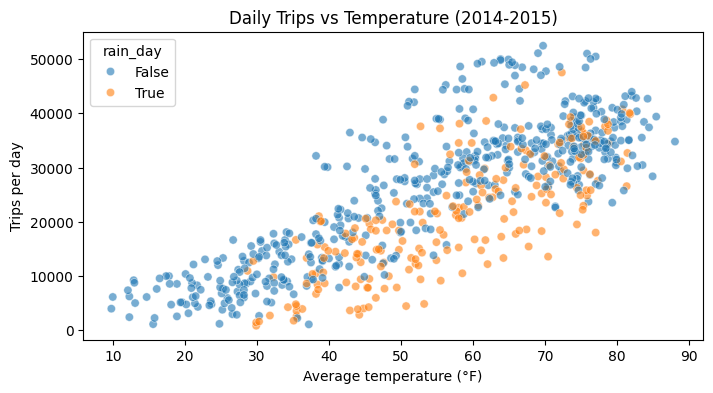

In [8]:
daily['temp_band'] = pd.cut(daily['avg_temp_f'], bins=[-50, 40, 60, 75, 120],
                            labels=['Below 40°F', '40-60°F', '60-75°F', '75°F+'])
print(daily.groupby('temp_band', observed=True)['trips'].agg(['count', 'mean']).round(0))

print(f"\nCorrelation (temperature vs trips): {daily['avg_temp_f'].corr(daily['trips']):.2f}")

# Rain effect, controlling for weekday vs weekend
rain = daily.groupby(['is_weekend', 'rain_day'])['trips'].mean().unstack().round(0)
rain['pct_change_on_rain'] = ((rain[True] / rain[False] - 1) * 100).round(1)
print("\nAverage trips: dry vs rain days")
print(rain)

plt.figure(figsize=(8, 4))
sns.scatterplot(data=daily, x='avg_temp_f', y='trips', hue='rain_day', alpha=0.6)
plt.title('Daily Trips vs Temperature (2014-2015)')
plt.xlabel('Average temperature (°F)')
plt.ylabel('Trips per day')
plt.savefig('images/weather_vs_trips.png', bbox_inches='tight')
plt.show()

In [9]:
from prophet import Prophet

df = daily[['trip_date', 'trips', 'avg_temp_f', 'rain_day']].rename(
    columns={'trip_date': 'ds', 'trips': 'y'})
df['rain_day'] = df['rain_day'].astype(int)

# Baseline: same day last week
df['naive_last_week'] = df['y'].shift(7)

train = df[df['ds'] < '2015-11-01']
test  = df[df['ds'] >= '2015-11-01']
print(f"Train: {len(train)} days | Test: {len(test)} days")

m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
m.add_country_holidays(country_name='US')
m.add_regressor('avg_temp_f')
m.add_regressor('rain_day')
m.fit(train[['ds', 'y', 'avg_temp_f', 'rain_day']])

fc = m.predict(test[['ds', 'avg_temp_f', 'rain_day']])
result = test.merge(fc[['ds', 'yhat', 'yhat_lower', 'yhat_upper']], on='ds')

mape_model = (abs(result['y'] - result['yhat']) / result['y']).mean() * 100
mape_naive = (abs(result['y'] - result['naive_last_week']) / result['y']).mean() * 100
coverage = ((result['y'] >= result['yhat_lower']) & (result['y'] <= result['yhat_upper'])).mean() * 100

print(f"Prophet MAPE:        {mape_model:.1f}%")
print(f"Naive baseline MAPE: {mape_naive:.1f}%")
print(f"Improvement:         {mape_naive - mape_model:.1f} percentage points")
print(f"Actuals inside 80% interval: {coverage:.0f}%")

Importing plotly failed. Interactive plots will not work.


Train: 669 days | Test: 61 days


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
18:44:52 - cmdstanpy - INFO - Chain [1] start processing
18:44:53 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE:        25.4%
Naive baseline MAPE: 35.7%
Improvement:         10.3 percentage points
Actuals inside 80% interval: 49%


In [10]:
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

df['precip_in'] = daily['precip_in'].values
df['temp_capped'] = df['avg_temp_f'].clip(upper=65)

def evaluate(train_df, holdout_df, log_y, yearly, regs):
    tr = train_df.copy()
    if log_y:
        tr['y'] = np.log(tr['y'])
    m = Prophet(yearly_seasonality=yearly, weekly_seasonality=True,
                daily_seasonality=False, interval_width=0.8)
    m.add_country_holidays(country_name='US')
    for r in regs:
        m.add_regressor(r)
    m.fit(tr[['ds', 'y'] + regs])
    fc = m.predict(holdout_df[['ds'] + regs])
    if log_y:
        for c in ['yhat', 'yhat_lower', 'yhat_upper']:
            fc[c] = np.exp(fc[c])
    res = holdout_df[['ds', 'y', 'naive_last_week']].merge(
        fc[['ds', 'yhat', 'yhat_lower', 'yhat_upper']], on='ds')
    mape = (abs(res['y'] - res['yhat']) / res['y']).mean() * 100
    cov = ((res['y'] >= res['yhat_lower']) & (res['y'] <= res['yhat_upper'])).mean() * 100
    return mape, cov, m, res

configs = {
    'A: original':                        (False, True,  ['avg_temp_f', 'rain_day']),
    'B: log trips':                       (True,  True,  ['avg_temp_f', 'rain_day']),
    'C: log + capped temp + precip':      (True,  True,  ['temp_capped', 'rain_day', 'precip_in']),
    'D: C without yearly seasonality':    (True,  False, ['temp_capped', 'rain_day', 'precip_in']),
}

train_v = df[df['ds'] < '2015-09-01']
val     = df[(df['ds'] >= '2015-09-01') & (df['ds'] < '2015-11-01')]

scores = []
for name, (log_y, yearly, regs) in configs.items():
    mape, cov, _, _ = evaluate(train_v, val, log_y, yearly, regs)
    scores.append({'model': name, 'val_MAPE': round(mape, 1), 'val_coverage_80': round(cov)})

scores = pd.DataFrame(scores).sort_values('val_MAPE')
print(scores.to_string(index=False))

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


                          model  val_MAPE  val_coverage_80
  C: log + capped temp + precip      14.6               95
D: C without yearly seasonality      15.4               95
                   B: log trips      21.8               89
                    A: original      22.0               23


In [11]:
best = scores.iloc[0]['model']
log_y, yearly, regs = configs[best]
print("Selected on validation:", best)

train = df[df['ds'] < '2015-11-01']
test  = df[df['ds'] >= '2015-11-01']
mape_test, cov_test, m, result = evaluate(train, test, log_y, yearly, regs)
mape_naive = (abs(result['y'] - result['naive_last_week']) / result['y']).mean() * 100

print(f"Test MAPE (final model):  {mape_test:.1f}%")
print(f"Test MAPE (naive):        {mape_naive:.1f}%")
print(f"Actuals inside 80% interval: {cov_test:.0f}%")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


Selected on validation: C: log + capped temp + precip
Test MAPE (final model):  17.9%
Test MAPE (naive):        35.7%
Actuals inside 80% interval: 90%


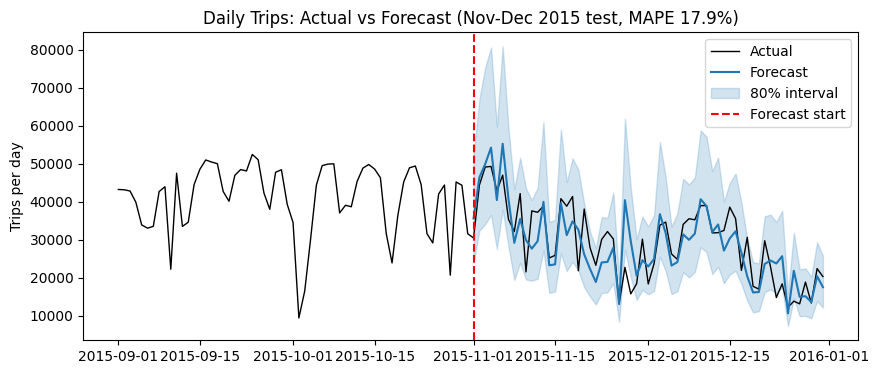

(730, 6)
          date  actual_trips  forecast_trips  forecast_lower  forecast_upper  \
725 2015-12-27         13113         14961.0         10464.0         22682.0   
726 2015-12-28         18840         15130.0         10367.0         22332.0   
727 2015-12-29         13324         13603.0          9177.0         19684.0   
728 2015-12-30         22403         20395.0         13887.0         30165.0   
729 2015-12-31         20290         17502.0         11785.0         26218.0   

    period  
725   Test  
726   Test  
727   Test  
728   Test  
729   Test  


In [12]:
# Chart: Sep-Dec 2015, actual vs forecast
recent = df[df['ds'] >= '2015-09-01']
plt.figure(figsize=(10, 4))
plt.plot(recent['ds'], recent['y'], label='Actual', color='black', linewidth=1)
plt.plot(result['ds'], result['yhat'], label='Forecast', color='tab:blue')
plt.fill_between(result['ds'], result['yhat_lower'], result['yhat_upper'],
                 color='tab:blue', alpha=0.2, label='80% interval')
plt.axvline(pd.Timestamp('2015-11-01'), color='red', linestyle='--', label='Forecast start')
plt.title(f'Daily Trips: Actual vs Forecast (Nov-Dec 2015 test, MAPE {mape_test:.1f}%)')
plt.ylabel('Trips per day')
plt.legend()
plt.savefig('images/forecast_vs_actual.png', bbox_inches='tight')
plt.show()

# Export for Tableau: model values for all 730 days + train/test label
full = m.predict(df[['ds'] + regs])
for c in ['yhat', 'yhat_lower', 'yhat_upper']:
    full[c] = np.exp(full[c])   # model was trained on log(trips)

export = df[['ds', 'y']].merge(full[['ds', 'yhat', 'yhat_lower', 'yhat_upper']], on='ds')
export[['yhat', 'yhat_lower', 'yhat_upper']] = export[['yhat', 'yhat_lower', 'yhat_upper']].round(0)
export['period'] = np.where(export['ds'] < '2015-11-01', 'Train', 'Test')
export.columns = ['date', 'actual_trips', 'forecast_trips', 'forecast_lower', 'forecast_upper', 'period']
export.to_csv('data/forecast.csv', index=False)
print(export.shape)
print(export.tail())